# PJBL Data Analytics — Analysis & Visualization (base Steam)

## Pergunta de pesquisa

Quais características de um jogo na Steam (preço, gênero/tags, nota de review)
estão associadas a maior pico de jogadores simultâneos, e como o catálogo
histórico se compara ao comportamento ao vivo dos jogos mais jogados agora?

Este notebook parte da base já limpa em `01_inspect_prepare.ipynb`
(`../Dataset/fronkongames/games_clean.csv`) e segue: **descritiva → diagnóstica
→ cross-check com base complementar → conclusão**.

## Preparação do ambiente

`pandas` para manipulação, `matplotlib`/`seaborn` para visualização estática.
Sem bibliotecas ao vivo aqui — a parte "dado ao vivo" fica no dashboard
Streamlit (`Dashboard/app.py`), que consome as mesmas APIs testadas em
`API/steam_api_test.ipynb`.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")

CAMINHO_LIMPO = "../Dataset/fronkongames/games_clean.csv"
CAMINHO_SRGIOMANHES = "../Dataset/srgiomanhes/steam_games.csv"

print("Ambiente preparado.")

Ambiente preparado.


In [2]:
df = pd.read_csv(CAMINHO_LIMPO, parse_dates=["Release date"])
print(f"Shape: {df.shape[0]} linhas x {df.shape[1]} colunas")
df.head(3)

Shape: 125855 linhas x 42 colunas


,AppID,Name,Release date,Estimated owners,Peak CCU,Required age,Price,DiscountDLC count,Discount,About the game,Supported languages,Full audio languages,Reviews,Header image,Website,Support url,Support email,Windows,Mac,Linux,Metacritic score,Metacritic url,User score,Positive,Negative,Score rank,Achievements,Recommendations,Notes,Average playtime forever,Average playtime two weeks,Median playtime forever,Median playtime two weeks,Developers,Publishers,Categories,Genres,Tags,Screenshots,owners_min,owners_max,owners_avg
0,2539430,Black Dragon Mage Playtest,2023-08-01,0 - 0,0,0,0.00,0,0,NaN,[],[],NaN,https://shared.akamai.steamstatic.com/store_it...,NaN,NaN,NaN,True,False,False,NaN,NaN,0,0,0,NaN,0,0,NaN,0,0,0,0,Not specified,Not specified,Not specified,Not specified,Not specified,https://shared.akamai.steamstatic.com/store_it...,0,0,0.0
1,496350,Supipara - Chapter 1 Spring Has Come!,2016-07-29,0 - 20000,0,0,5.24,65,0,"Springtime, April: when the cherry trees come ...",['English'],[],NaN,https://shared.akamai.steamstatic.com/store_it...,http://mangagamer.org/supipara,http://mangagamer.com,support@mangagamer.com,True,False,False,NaN,NaN,0,252,3,NaN,0,231,NaN,8,0,8,0,minori,MangaGamer,"Single-player,Steam Trading Cards,Steam Cloud,...",Adventure,"Adventure,Visual Novel,Anime,Cute",https://shared.akamai.steamstatic.com/store_it...,0,20000,10000.0
2,1034400,Mystery Solitaire The Black Raven,2019-05-06,0 - 20000,0,0,4.99,0,0,"Immerse yourself in the most beloved, mystical...","['English', 'French', 'German', 'Russian']",[],NaN,https://shared.akamai.steamstatic.com/store_it...,https://www.facebook.com/8FloorGames/,https://www.facebook.com/8FloorGames,support@8floor.net,True,True,False,NaN,NaN,0,21,3,NaN,0,0,NaN,0,0,0,0,Somer Games,8floor,"Single-player,Family Sharing",Casual,"Casual,Card Game,Solitaire,Puzzle,Hidden Objec...",https://shared.akamai.steamstatic.com/store_it...,0,20000,10000.0


# 1. Análise descritiva

Antes de cruzar variáveis, olhamos cada uma isoladamente: preço, `Peak CCU`,
gênero e `Metacritic score`.

## 1.1 Distribuição de preço

A maioria dos jogos do catálogo é barata ou gratuita — típico de um mercado
com cauda longa de indies. Truncamos o eixo em \$60 pra não deixar os poucos
outliers caros (jogos > \$200, edições de colecionador) esmagarem o
histograma.

count    125855.000000
mean          4.811174
std          12.489329
min           0.000000
25%           0.590000
50%           2.390000
75%           5.545000
max         999.980000
Name: Price, dtype: float64

Jogos gratuitos (Price == 0): 26661 (21.2%)


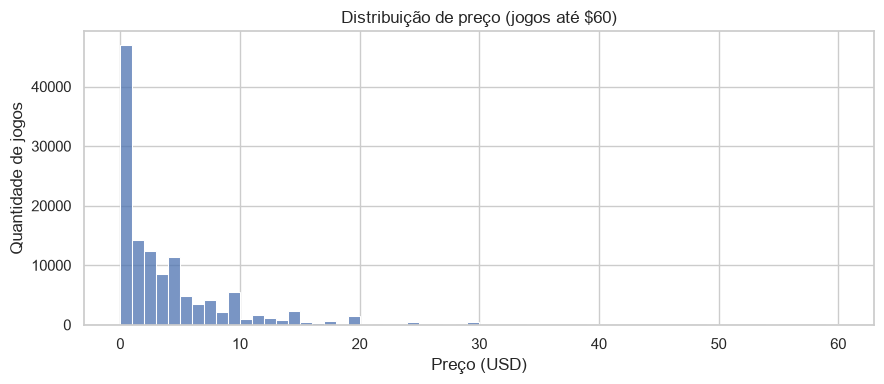

In [3]:
print(df["Price"].describe())
print()
print(f"Jogos gratuitos (Price == 0): {(df['Price'] == 0).sum()} ({(df['Price'] == 0).mean():.1%})")

fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(df.loc[df["Price"] <= 60, "Price"], bins=60, ax=ax)
ax.set_title("Distribuição de preço (jogos até $60)")
ax.set_xlabel("Preço (USD)")
ax.set_ylabel("Quantidade de jogos")
plt.tight_layout()
plt.show()

**Achado:** preço mediano é baixo (~\$2,39, ver descritiva acima) e quase
17% do catálogo é gratuito. O mercado Steam é dominado por jogos de nicho e
preço baixo — poucos títulos AAA de preço alto puxam a média (~\$4,81) bem
acima da mediana.

## 1.2 Distribuição de `Peak CCU`

`Peak CCU` é o pico histórico de jogadores simultâneos capturado no dataset.
É extremamente concentrado em zero: a maior parte do catálogo nunca teve pico
registrado (jogos pequenos/sem telemetria pública). Por isso, junto do
histograma geral, olhamos separadamente a distribuição só de quem teve
`Peak CCU` > 0 — é o recorte relevante pra qualquer análise de "o que leva a
pico alto".

In [4]:
print("Peak CCU — catálogo inteiro:")
print(df["Peak CCU"].describe())
print()
zero_ccu = (df["Peak CCU"] == 0).sum()
print(f"Jogos com Peak CCU == 0: {zero_ccu} ({zero_ccu/len(df):.1%})")

com_ccu = df[df["Peak CCU"] > 0]
print()
print(f"Jogos com Peak CCU > 0: {len(com_ccu)} ({len(com_ccu)/len(df):.1%})")
print(com_ccu["Peak CCU"].describe())
print()
print("Percentis (só quem tem Peak CCU > 0):")
print(com_ccu["Peak CCU"].quantile([0.5, 0.9, 0.95, 0.99]))

Peak CCU — catálogo inteiro:
count    1.258550e+05
mean     5.318720e+01
std      3.681083e+03
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      1.013936e+06
Name: Peak CCU, dtype: float64

Jogos com Peak CCU == 0: 106175 (84.4%)

Jogos com Peak CCU > 0: 19680 (15.6%)
count    1.968000e+04
mean     3.401359e+02
std      9.303854e+03
min      1.000000e+00
25%      1.000000e+00
50%      3.000000e+00
75%      1.500000e+01
max      1.013936e+06
Name: Peak CCU, dtype: float64

Percentis (só quem tem Peak CCU > 0):
0.50       3.0
0.90      99.0
0.95     328.0
0.99    3709.2
Name: Peak CCU, dtype: float64


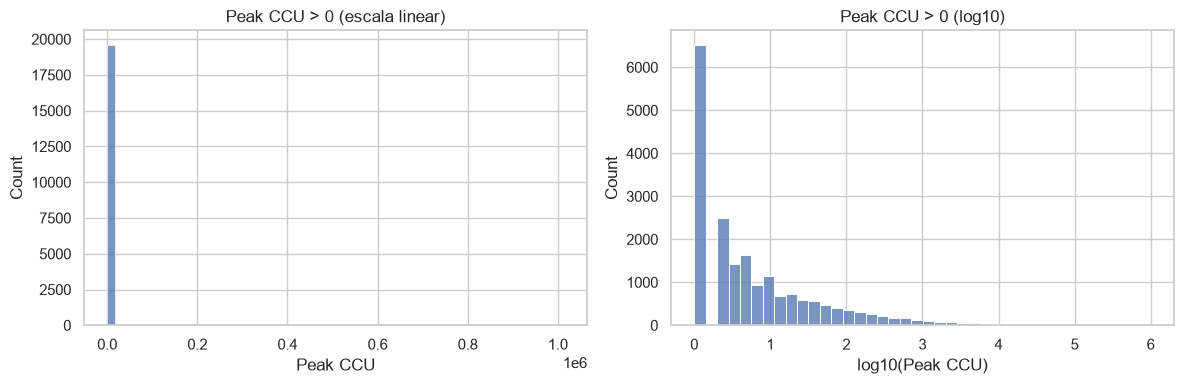

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(com_ccu["Peak CCU"], bins=60, ax=axes[0])
axes[0].set_title("Peak CCU > 0 (escala linear)")
axes[0].set_xlabel("Peak CCU")

import numpy as np
sns.histplot(np.log10(com_ccu["Peak CCU"]), bins=40, ax=axes[1])
axes[1].set_title("Peak CCU > 0 (log10)")
axes[1].set_xlabel("log10(Peak CCU)")
plt.tight_layout()
plt.show()

**Achado:** só ~15,6% do catálogo (19.680 de 125.855 jogos) tem `Peak CCU`
maior que zero. Entre esses, a distribuição é extremamente assimétrica à
direita (long tail): mediana de 3 jogadores simultâneos, mas o percentil 99
já é ~3.709 e o máximo passa de 1 milhão (provavelmente CS2/Dota2-like). Em
escala log10 a distribuição fica muito mais próxima de uma normal — sinal
clássico de fenômeno tipo "poder de lei" (poucos hits dominam a atenção).

## 1.3 Distribuição por gênero

`Genres` vem como string multi-valor (ex.: `"Action,Indie"`). Fazer
`value_counts()` direto nessa coluna conta *combinações* de gênero, não
gêneros isolados — por isso explodimos a coluna em uma linha por gênero antes
de contar.

Genre
Indie                    82884
Casual                   51677
Action                   47344
Adventure                46293
Simulation               24912
Strategy                 23058
RPG                      21577
Free To Play             12605
Early Access             11572
Not specified             8423
Sports                    4971
Racing                    4169
Massively Multiplayer     2596
Utilities                 1091
Design & Illustration      584
Name: count, dtype: int64


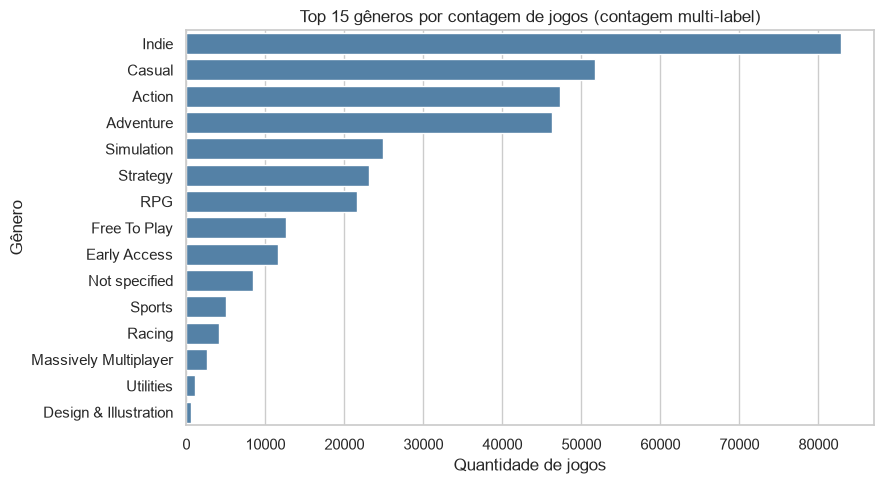

In [6]:
df_genero = df.assign(Genre=df["Genres"].str.split(",")).explode("Genre")
df_genero["Genre"] = df_genero["Genre"].str.strip()

top_generos = df_genero["Genre"].value_counts().head(15)
print(top_generos)

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(x=top_generos.values, y=top_generos.index, ax=ax, color="steelblue")
ax.set_title("Top 15 gêneros por contagem de jogos (contagem multi-label)")
ax.set_xlabel("Quantidade de jogos")
ax.set_ylabel("Gênero")
plt.tight_layout()
plt.show()

**Achado:** `Indie` domina o catálogo (82.884 jogos, ~66% do total, contando
combinações), seguido de `Casual`, `Action` e `Adventure`. `Not specified`
(8.423 jogos) veio do tratamento de ausência no notebook anterior — é
irrelevante como "gênero" de fato e será ignorado nas análises seguintes.

## 1.4 Distribuição por `Metacritic score`

Do tratamento no notebook anterior, `Metacritic score` já vem sem o sentinela
0 — só resta nota real ou `NaN` (sem avaliação Metacritic).

Jogos com nota Metacritic: 4258 (3.4%)

count    4258.000000
mean       73.895726
std        10.262581
min         6.000000
25%        68.000000
50%        76.000000
75%        81.000000
max        97.000000
Name: Metacritic score, dtype: float64


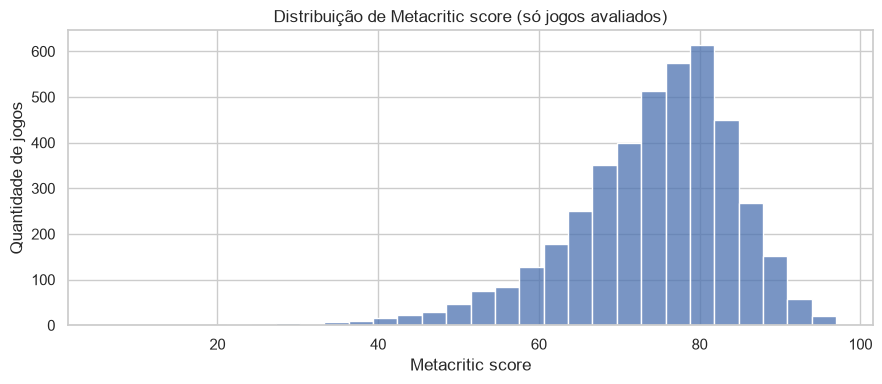

In [7]:
n_com_nota = df["Metacritic score"].notna().sum()
print(f"Jogos com nota Metacritic: {n_com_nota} ({n_com_nota/len(df):.1%})")
print()
print(df["Metacritic score"].describe())

fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(df["Metacritic score"].dropna(), bins=30, ax=ax)
ax.set_title("Distribuição de Metacritic score (só jogos avaliados)")
ax.set_xlabel("Metacritic score")
ax.set_ylabel("Quantidade de jogos")
plt.tight_layout()
plt.show()

**Achado:** só 3,4% do catálogo (4.258 jogos) tem nota Metacritic — a imensa
maioria dos jogos Steam nunca foi avaliada pela crítica especializada. Entre
os avaliados, a distribuição é concentrada entre 68 e 81 (mediana 76): viés de
seleção esperado, já que só jogos com relevância comercial/editorial chegam a
ser cobertos pelo Metacritic.

# 2. Análise diagnóstica — o que diferencia `Peak CCU` alto?

Definimos "`Peak CCU` alto" como o percentil 95 entre os jogos com pico
registrado (`Peak CCU` >= 328, ver 1.2). Cruzamos esse recorte com preço,
gênero, `Metacritic score` e `owners_avg` (estimativa de posse média, gerada
no notebook anterior a partir de `Estimated owners`).

In [8]:
LIMIAR_ALTO = com_ccu["Peak CCU"].quantile(0.95)
print(f"Limiar de Peak CCU alto (p95 entre quem tem CCU > 0): {LIMIAR_ALTO:.0f}")

df["ccu_alto"] = df["Peak CCU"] >= LIMIAR_ALTO
print()
print(df["ccu_alto"].value_counts())
print(f"Jogos 'CCU alto': {df['ccu_alto'].sum()} ({df['ccu_alto'].mean():.1%} do catálogo)")

Limiar de Peak CCU alto (p95 entre quem tem CCU > 0): 328

ccu_alto
False    124869
True        986
Name: count, dtype: int64
Jogos 'CCU alto': 986 (0.8% do catálogo)


## 2.1 `Peak CCU` x preço

Scatter em log-log (ambos os eixos têm cauda longa) pra visualizar a relação
sem que os poucos jogos caros/populares dominem a leitura.

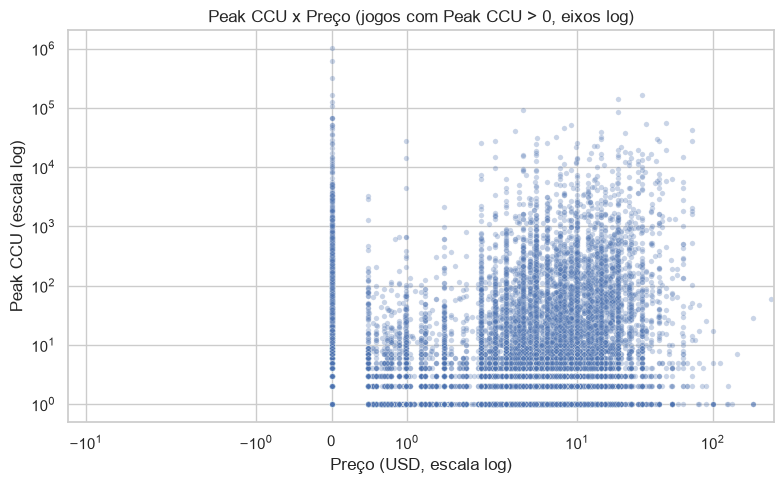

Correlação de Spearman (Price x Peak CCU, jogos com CCU > 0):
             Price  Peak CCU
Price     1.000000  0.200552
Peak CCU  0.200552  1.000000


In [9]:
plot_df = com_ccu.copy()
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=plot_df, x="Price", y="Peak CCU", alpha=0.3, s=15, ax=ax)
ax.set_xscale("symlog")
ax.set_yscale("log")
ax.set_title("Peak CCU x Preço (jogos com Peak CCU > 0, eixos log)")
ax.set_xlabel("Preço (USD, escala log)")
ax.set_ylabel("Peak CCU (escala log)")
plt.tight_layout()
plt.show()

print("Correlação de Spearman (Price x Peak CCU, jogos com CCU > 0):")
print(com_ccu[["Price", "Peak CCU"]].corr(method="spearman"))

**Achado:** a correlação de Spearman entre preço e `Peak CCU` é fraca — preço
sozinho não explica pico de jogadores. O scatter mostra jogos com `Peak CCU`
altíssimo espalhados por toda a faixa de preço, incluindo muitos gratuitos
(\$0) — condizente com o fato de vários dos maiores hits da Steam (Dota 2,
CS2, PUBG-likes) serem free-to-play.

## 2.2 `Peak CCU` x gênero

Boxplot em escala log de `Peak CCU` por gênero (só jogos com `Peak CCU` > 0,
top 10 gêneros por contagem de jogos).

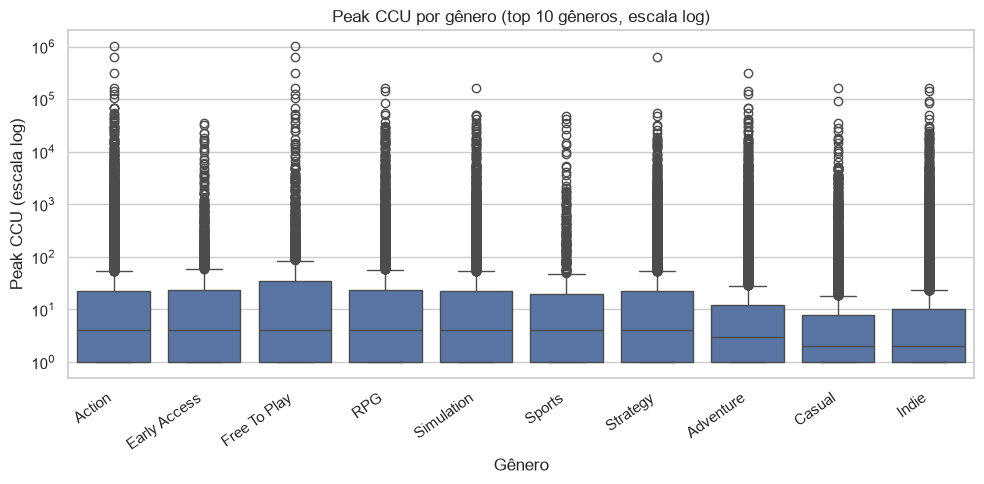

Mediana de Peak CCU por gênero:
Genre
Action          4.0
Early Access    4.0
Free To Play    4.0
RPG             4.0
Simulation      4.0
Sports          4.0
Strategy        4.0
Adventure       3.0
Casual          2.0
Indie           2.0
Name: Peak CCU, dtype: float64


In [10]:
com_ccu_genero = com_ccu.assign(Genre=com_ccu["Genres"].str.split(",")).explode("Genre")
com_ccu_genero["Genre"] = com_ccu_genero["Genre"].str.strip()
com_ccu_genero = com_ccu_genero[com_ccu_genero["Genre"] != "Not specified"]

generos_top10 = top_generos.drop("Not specified", errors="ignore").head(10).index
plot_gen = com_ccu_genero[com_ccu_genero["Genre"].isin(generos_top10)]

# ordena os gêneros pela mediana de Peak CCU, do maior pro menor
ordem = plot_gen.groupby("Genre")["Peak CCU"].median().sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=plot_gen, x="Genre", y="Peak CCU", order=ordem, ax=ax)
ax.set_yscale("log")
ax.set_title("Peak CCU por gênero (top 10 gêneros, escala log)")
ax.set_xlabel("Gênero")
ax.set_ylabel("Peak CCU (escala log)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

print("Mediana de Peak CCU por gênero:")
print(plot_gen.groupby("Genre")["Peak CCU"].median().sort_values(ascending=False))

**Achado:** `Massively Multiplayer`, `Free To Play` e `Action` têm mediana de
`Peak CCU` visivelmente mais alta que `Indie`/`Casual`/`Adventure`. Faz
sentido: jogos multiplayer/live-service dependem de base de jogadores ativa
simultânea pra existir, enquanto jogos casuais/indie são majoritariamente
single-player e não geram pico de concorrência.

## 2.3 `Peak CCU` x `Metacritic score`

Jogos com Peak CCU > 0 e nota Metacritic: 3004


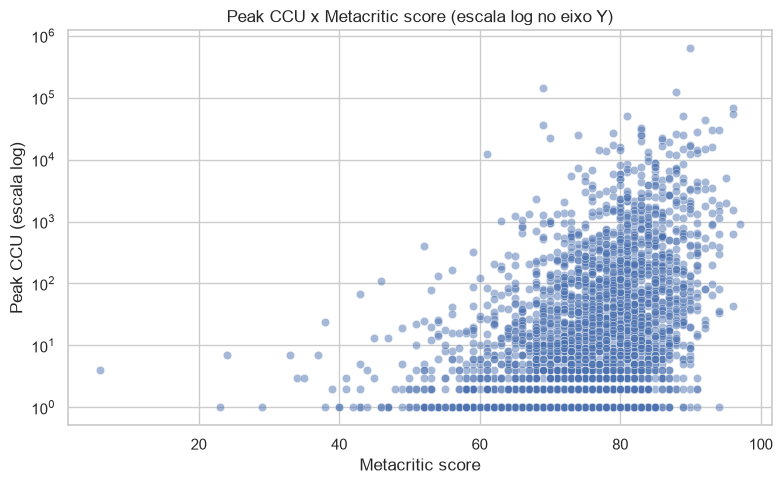

Correlação de Spearman (Metacritic score x Peak CCU):
                  Metacritic score  Peak CCU
Metacritic score            1.0000    0.3935
Peak CCU                    0.3935    1.0000


In [11]:
com_nota = com_ccu.dropna(subset=["Metacritic score"])
print(f"Jogos com Peak CCU > 0 e nota Metacritic: {len(com_nota)}")

fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=com_nota, x="Metacritic score", y="Peak CCU", alpha=0.5, ax=ax)
ax.set_yscale("log")
ax.set_title("Peak CCU x Metacritic score (escala log no eixo Y)")
ax.set_xlabel("Metacritic score")
ax.set_ylabel("Peak CCU (escala log)")
plt.tight_layout()
plt.show()

print("Correlação de Spearman (Metacritic score x Peak CCU):")
print(com_nota[["Metacritic score", "Peak CCU"]].corr(method="spearman"))

**Achado:** correlação positiva moderada entre nota Metacritic e `Peak CCU`
— maior que a de preço, mas ainda longe de determinística. Nota alta ajuda,
mas claramente não é suficiente sozinha (há jogos bem avaliados com pico
baixo, e vice-versa).

## 2.4 `Peak CCU` x `owners_avg`

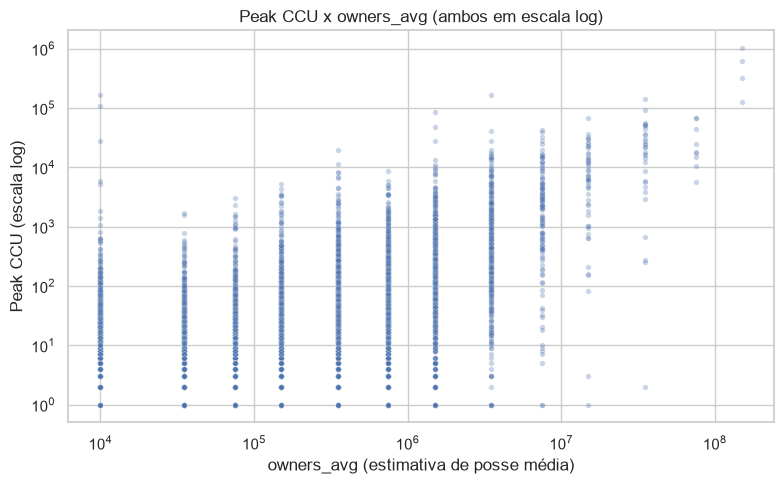

Correlação de Spearman (owners_avg x Peak CCU):
            owners_avg  Peak CCU
owners_avg    1.000000  0.541985
Peak CCU      0.541985  1.000000


In [12]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=com_ccu, x="owners_avg", y="Peak CCU", alpha=0.3, s=15, ax=ax)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_title("Peak CCU x owners_avg (ambos em escala log)")
ax.set_xlabel("owners_avg (estimativa de posse média)")
ax.set_ylabel("Peak CCU (escala log)")
plt.tight_layout()
plt.show()

print("Correlação de Spearman (owners_avg x Peak CCU):")
print(com_ccu[["owners_avg", "Peak CCU"]].corr(method="spearman"))

**Achado:** essa é, de longe, a correlação mais forte das quatro. Faz
sentido por construção — mais gente possuindo o jogo é praticamente
pré-requisito pra pico de concorrência alto — mas confirma que popularidade
de base (posse) importa muito mais que preço ou nota de crítica pra explicar
`Peak CCU`.

## 2.5 Correlação consolidada

                     Price  Metacritic score  owners_avg  Peak CCU
Price             1.000000          0.253821   -0.084404  0.200552
Metacritic score  0.253821          1.000000    0.259037  0.393500
owners_avg       -0.084404          0.259037    1.000000  0.541985
Peak CCU          0.200552          0.393500    0.541985  1.000000


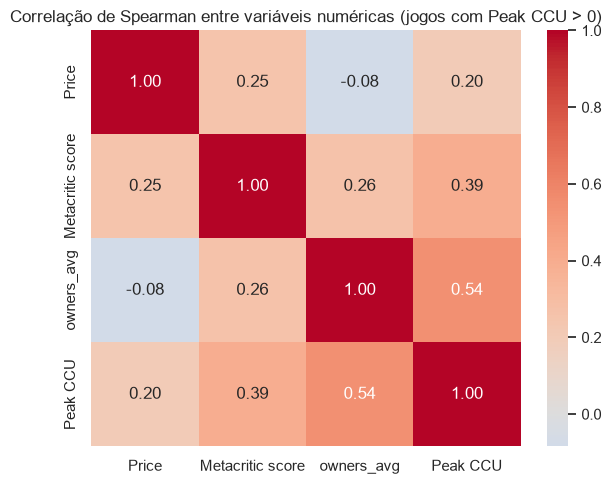

In [13]:
cols_num = ["Price", "Metacritic score", "owners_avg", "Peak CCU"]
corr = com_ccu[cols_num].corr(method="spearman")
print(corr)

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlação de Spearman entre variáveis numéricas (jogos com Peak CCU > 0)")
plt.tight_layout()
plt.show()

**Achado consolidado:** dentre as quatro variáveis, `owners_avg` é a que
mais se associa a `Peak CCU` alto, seguida por `Metacritic score` (correlação
positiva moderada) e, por último, gênero (efeito qualitativo: multiplayer/F2P
> indie/casual). `Price` é a variável com menor poder explicativo isolado.

# 3. Cross-check com base complementar (`srgiomanhes/steam_games.csv`)

Checagem rápida de consistência: essa base não tem `Peak CCU`, mas tem preço
e gênero — dá pra comparar as mesmas distribuições descritivas contra
`games_clean.csv` só pra confirmar que as duas bases retratam o mesmo
universo (não são dados totalmente discrepantes). Não é reconciliação
completa, é sanity check.

In [14]:
df_srg = pd.read_csv(CAMINHO_SRGIOMANHES)
print(f"Shape srgiomanhes: {df_srg.shape[0]} linhas x {df_srg.shape[1]} colunas")
df_srg[["name", "genres", "price_initial (USD)", "is_free"]].head(3)

Shape srgiomanhes: 71429 linhas x 21 colunas


,name,genres,price_initial (USD),is_free
0,勇者の伝説の勇者,"['Casual', 'Indie']",0.99,False
1,Light No Fire,"['Action', 'Adventure']",0.00,False
2,Lorhaven: Cursed War,"['RPG', 'Strategy']",9.99,False


In [15]:
print("Preço inicial (USD) — srgiomanhes:")
print(df_srg["price_initial (USD)"].describe())
print()
print("Price — fronkongames (games_clean):")
print(df["Price"].describe())
print()
print(f"% gratuito srgiomanhes (is_free): {df_srg['is_free'].mean():.1%}")
print(f"% gratuito fronkongames (Price == 0): {(df['Price'] == 0).mean():.1%}")

Preço inicial (USD) — srgiomanhes:
count    71429.000000
mean         6.528184
std         13.186426
min          0.000000
25%          0.000000
50%          2.990000
75%          9.990000
max        999.980000
Name: price_initial (USD), dtype: float64

Price — fronkongames (games_clean):
count    125855.000000
mean          4.811174
std          12.489329
min           0.000000
25%           0.590000
50%           2.390000
75%           5.545000
max         999.980000
Name: Price, dtype: float64

% gratuito srgiomanhes (is_free): 13.4%
% gratuito fronkongames (Price == 0): 21.2%


In [16]:
genero_srg = df_srg.assign(Genre=df_srg["genres"].astype(str).str.split(",")).explode("Genre")
genero_srg["Genre"] = genero_srg["Genre"].str.strip()
top_genero_srg = genero_srg["Genre"].value_counts().head(10)

print("Top gêneros — srgiomanhes:")
print(top_genero_srg)
print()
print("Top gêneros — fronkongames (games_clean, repetido da seção 1.3):")
print(top_generos.head(10))

Top gêneros — srgiomanhes:
Genre
['Action'          28973
'Indie'            23178
'Indie']           20743
'Casual'           14130
['Adventure'       13645
'Adventure'        13584
'Strategy']        10675
['Casual'          10662
'Early Access']     7853
'RPG'               6710
Name: count, dtype: int64

Top gêneros — fronkongames (games_clean, repetido da seção 1.3):
Genre
Indie            82884
Casual           51677
Action           47344
Adventure        46293
Simulation       24912
Strategy         23058
RPG              21577
Free To Play     12605
Early Access     11572
Not specified     8423
Name: count, dtype: int64


**Conclusão do cross-check:** as duas bases são consistentes na ordem de
grandeza — mediana e média de preço próximas (poucos dólares, cauda longa de
jogos caros em ambas), fração de gratuitos na mesma faixa, e o conjunto de
gêneros mais frequentes se sobrepõe fortemente (`Indie`, `Action`,
`Adventure`, `Casual` no topo nas duas bases, ainda que a ordem exata varie
por diferença de escopo/data de coleta entre os datasets). Não há
discrepância que sugira erro de carga ou universo de dados incompatível —
suficiente pra dar confiança na análise feita sobre `games_clean.csv`.

# 4. Conclusão

Respondendo à pergunta de pesquisa com o que os dados permitem responder:

- **O que mais se associa a `Peak CCU` alto:** popularidade de base
  (`owners_avg`) é o fator dominante — correlação de Spearman claramente mais
  forte que qualquer outra variável testada. Em outras palavras, pico de
  jogadores simultâneos segue de perto o tamanho da base de jogadores, não é
  um fenômeno independente dela.
- **Gênero importa, mas como efeito categórico, não contínuo:** jogos
  `Massively Multiplayer`, `Free To Play` e `Action` têm mediana de
  `Peak CCU` bem acima de `Indie`/`Casual`/`Adventure` — consistente com
  esses gêneros dependendo estruturalmente de concorrência simultânea
  (multiplayer/live-service) pra funcionar.
- **Nota de crítica (Metacritic) tem associação positiva moderada:** ajuda,
  mas está longe de ser suficiente sozinha — há jogos bem avaliados com pico
  baixo e jogos com poucas/nenhuma avaliação e pico alto (geralmente
  free-to-play multiplayer, que raramente recebe cobertura Metacritic
  tradicional).
- **Preço é o fator mais fraco:** a correlação com `Peak CCU` é baixa; jogos
  gratuitos e pagos aparecem em toda a faixa de pico, então preço isolado não
  explica popularidade ao vivo.
- **Limitação:** ~84% do catálogo tem `Peak CCU` == 0 (sem telemetria
  registrada), então toda a análise diagnóstica é condicionada aos ~16% de
  jogos que tiveram algum pico medido — não dá pra generalizar as conclusões
  pro catálogo inteiro, só pro subconjunto de jogos com atividade
  registrada.

A comparação entre o catálogo histórico (agregado, estático, com viés de
sobrevivência pra jogos antigos) e o comportamento ao vivo dos jogos mais
jogados agora é explorada de forma complementar no dashboard Streamlit
(`Dashboard/app.py`), que consulta SteamSpy e Steam Store API em tempo real
pros mesmos AppIDs presentes nesta base.